In [ ]:
# UN Noon Briefings — Sentiment & Tone Visualization

This notebook is used to visualize the sentiment and tone results that are already stored in the database.

The `sentiment_analysis` and `analysis_run` tables should already contain the analysis results before running this notebook. This notebook does not run the sentiment analysis again or use Ollama. It only loads the existing results from `data/briefings.db` and creates visualizations from them.

If the tables do not contain any analysis results, the sentiment analysis pipeline needs to be run first.

### Visualizations included

1. Analysis-run summary
2. Sentiment distribution
3. Tone distribution
4. Sentiment over time
5. Tone over time
6. Sentiment and tone heatmap
7. Monthly sentiment composition
8. Number of analysed sections per month


# UN Noon Briefings — Sentiment & Tone Visualization

This notebook is the **visualization stage** of the existing UN Noon Briefings sentiment/tone pipeline.

It is designed for the database structure used by `UN_Sentiment_Tone_Processing_Production`:

- `analysis_run`
- `sentiment_analysis`
- `briefing`
- `section`

The notebook **does not run Ollama or perform sentiment analysis again**. It reads the results already stored in `data/briefings.db`.The `sentiment_analysis` and `analysis_run` tables should already contain the analysis results before running this notebook. This notebook does not run the sentiment analysis again or use Ollama. It only loads the existing results from `data/briefings.db` and creates visualizations from them.

If the tables do not contain any analysis results, the sentiment analysis pipeline needs to be run first.
The following is the command for running sentiment analysis
- `pipenv run python un_llm_analysis/sentiment_tone_analysis.py`
 

### Visualizations included

1. Analysis-run overview
2. Sentiment distribution
3. Tone distribution
4. Sentiment percentage
5. Sentiment over time
6. Sentiment percentage over time
7. Tone over time
8. Sentiment × tone heatmap
9. Number of analysed sections per month
10. Monthly sentiment composition
11. Sentiment by briefing
12. Example sections behind sentiment/tone classifications
13. Export of dashboard-ready CSV data

> If your database is in a different location, change `DB_PATH` in the configuration cell.


## 0. Import libraries and configure the database

In [1]:

from pathlib import Path
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

PROJECT_ROOT = Path(r"E:\correlaid-mentoring-project")
DB_PATH = PROJECT_ROOT / "data" / "briefings.db"

OUTPUT_DIR = PROJECT_ROOT / "data" / "visualization"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Database:", DB_PATH)
print("Database exists:", DB_PATH.exists())
print("Visualization output directory:", OUTPUT_DIR)


Database: E:\correlaid-mentoring-project\data\briefings.db
Database exists: True
Visualization output directory: E:\correlaid-mentoring-project\data\visualization


In [2]:

# Automatic fallback paths in case the notebook is moved.
if not DB_PATH.exists():
    fallback_paths = [
        Path.cwd() / "data" / "briefings.db",
        Path.cwd().parent / "data" / "briefings.db",
        Path.cwd().parent.parent / "data" / "briefings.db",
    ]
    for candidate in fallback_paths:
        if candidate.exists():
            DB_PATH = candidate
            break

if not DB_PATH.exists():
    raise FileNotFoundError(
        f"Could not find briefings.db. Please update DB_PATH. Current path: {DB_PATH}"
    )

conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON")

print("Connected successfully.")
print("Using:", DB_PATH)


Connected successfully.
Using: E:\correlaid-mentoring-project\data\briefings.db


## 1. Inspect the database

In [3]:

tables_df = pd.read_sql_query(
    '''
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
    ORDER BY name
    ''',
    conn
)

display(tables_df)

print("\nDatabase tables and row counts:")
for table in tables_df["name"]:
    count = pd.read_sql_query(
        f'SELECT COUNT(*) AS count FROM "{table}"',
        conn
    ).iloc[0]["count"]
    print(f"  {table}: {count:,} rows")


,name
0,analysis_run
1,briefing
2,sdg
3,section
4,sentiment_analysis
5,sqlite_sequence



Database tables and row counts:
  analysis_run: 17 rows
  briefing: 407 rows
  sdg: 0 rows
  section: 2,970 rows
  sentiment_analysis: 1,000 rows
  sqlite_sequence: 2 rows



## 2. Select the analysis run

The production notebook creates an `analysis_run` record for each analysis run.
This visualization notebook uses the **latest analysis run containing successful
sentiment/tone results**.

Set `ANALYSIS_ID` manually if you want to visualize an older run.


In [4]:

ANALYSIS_ID = None  # Example: 1. None = automatically select latest successful run.

analysis_runs = pd.read_sql_query(
    '''
    SELECT
        ar.analysis_id,
        ar.analysis_name,
        ar.model_name,
        ar.model_version,
        ar.ollama_version,
        ar.prompt_version,
        ar.temperature,
        ar.created_at,
        COUNT(sa.analysis_result_id) AS stored_results,
        SUM(CASE WHEN sa.status = 'success' THEN 1 ELSE 0 END) AS successful_results,
        SUM(CASE WHEN sa.status = 'error' THEN 1 ELSE 0 END) AS error_results
    FROM analysis_run AS ar
    LEFT JOIN sentiment_analysis AS sa
        ON ar.analysis_id = sa.analysis_id
    GROUP BY ar.analysis_id
    ORDER BY ar.analysis_id DESC
    ''',
    conn
)

display(analysis_runs)

if ANALYSIS_ID is None:
    successful_runs = analysis_runs[
        analysis_runs["successful_results"].fillna(0) > 0
    ]
    if successful_runs.empty:
        raise ValueError("No analysis run with successful results was found.")
    ANALYSIS_ID = int(successful_runs.iloc[0]["analysis_id"])

print(f"Selected analysis_id: {ANALYSIS_ID}")


,analysis_id,analysis_name,model_name,model_version,ollama_version,prompt_version,temperature,created_at,stored_results,successful_results,error_results
0,17,UN briefing sentiment and tone analysis,llama3.2,ollama,NaN,v1.2,0.0,2026-09-26T12:05:08.333185,580,580,0
1,16,UN briefing sentiment and tone analysis,llama3.2,ollama,NaN,v1.2,0.0,2026-09-26T11:53:52.250129,0,0,0
2,15,UN briefing sentiment and tone analysis,llama3.2,ollama,NaN,v1.2,0.0,2026-09-26T07:00:59.728992,0,0,0
3,14,UN briefing sentiment and tone analysis,llama3.2,ollama,NaN,v1.2,0.0,2026-09-26T06:42:01.132073,0,0,0
4,13,UN briefing sentiment and tone analysis,llama3.2,ollama,NaN,v1.2,0.0,2026-09-25T07:09:58.151132,0,0,0
5,12,UN briefing sentiment and tone analysis,llama3.2,available-from-ollama-show,0.6.2,v1.1-production,0.0,2026-09-21T04:58:09.497418+00:00,0,0,0
6,11,UN briefing sentiment and tone analysis,llama3.2,available-from-ollama-show,0.6.2,v1.1-production,0.0,2026-09-20T09:29:03.803452+00:00,4300,2631,1669
7,10,UN briefing sentiment and tone analysis,llama3.2,available-from-ollama-show,0.6.2,v1.1-production,0.0,2026-09-20T09:26:23.952214+00:00,0,0,0
8,9,UN briefing sentiment and tone analysis,llama3.2,available-from-ollama-show,0.6.2,v1.1-production,0.0,2026-09-20T05:05:34.169950+00:00,320,320,0
9,8,UN briefing sentiment and tone analysis,llama3.2,available-from-ollama-show,0.6.2,v1.1-production,0.0,2026-09-19T19:43:23.375294+00:00,0,0,0


Selected analysis_id: 17


## 3. Display metadata for the selected analysis

In [5]:

metadata_df = pd.read_sql_query(
    '''
    SELECT
        analysis_id,
        analysis_name,
        model_name,
        model_version,
        ollama_version,
        prompt_version,
        temperature,
        created_at
    FROM analysis_run
    WHERE analysis_id = ?
    ''',
    conn,
    params=(ANALYSIS_ID,)
)

if metadata_df.empty:
    raise ValueError(f"Analysis ID {ANALYSIS_ID} does not exist.")

display(metadata_df)


,analysis_id,analysis_name,model_name,model_version,ollama_version,prompt_version,temperature,created_at
0,17,UN briefing sentiment and tone analysis,llama3.2,ollama,None,v1.2,0.0,2026-09-26T12:05:08.333185



## 4. Load successful sentiment/tone results

Only rows with `status = 'success'` are used for visualization.
The notebook reads the existing results; it does **not** call Ollama.


In [6]:

results_df = pd.read_sql_query(
    '''
    SELECT
        sa.analysis_id,
        sa.briefing_id,
        sa.section_id,
        sa.briefing_date,
        sa.sentiment,
        sa.tone,
        sa.status,
        sa.created_at
    FROM sentiment_analysis AS sa
    WHERE sa.analysis_id = ?
      AND sa.status = 'success'
    ORDER BY sa.briefing_date, sa.briefing_id, sa.section_id
    ''',
    conn,
    params=(ANALYSIS_ID,)
)

results_df["briefing_date"] = pd.to_datetime(
    results_df["briefing_date"], errors="coerce"
)

results_df["created_at"] = pd.to_datetime(
    results_df["created_at"], errors="coerce", utc=True
)

print(f"Successful analysis results: {len(results_df):,}")
print(f"Unique briefings: {results_df['briefing_id'].nunique():,}")
print(f"Unique sections: {results_df['section_id'].nunique():,}")
print(
    f"Date range: {results_df['briefing_date'].min()} "
    f"to {results_df['briefing_date'].max()}"
)

display(results_df.head())


Successful analysis results: 580
Unique briefings: 60
Unique sections: 580
Date range: 2025-08-01 00:00:00 to 2025-10-24 00:00:00


,analysis_id,briefing_id,section_id,briefing_date,sentiment,tone,status,created_at
0,17,20250801,2025080101,2025-08-01,Positive,Neutral/Informational,success,2026-09-26 12:07:03.494523+00:00
1,17,20250801,2025080102,2025-08-01,Neutral,Neutral/Informational,success,2026-09-26 12:07:03.457466+00:00
2,17,20250801,2025080103,2025-08-01,Negative,Concerned,success,2026-09-26 12:07:03.495568+00:00
3,17,20250801,2025080104,2025-08-01,Negative,Concerned,success,2026-09-26 12:07:03.498650+00:00
4,17,20250801,2025080105,2025-08-01,Negative,Urgent,success,2026-09-26 12:07:03.498650+00:00


## 5. Quality checks

In [7]:

print("Missing values:")
display(
    results_df[
        ["briefing_id", "section_id", "briefing_date", "sentiment", "tone"]
    ].isna().sum()
)

print("\nSentiment categories:")
display(
    results_df["sentiment"]
    .value_counts(dropna=False)
    .rename_axis("sentiment")
    .reset_index(name="count")
)

print("\nTone categories:")
display(
    results_df["tone"]
    .value_counts(dropna=False)
    .rename_axis("tone")
    .reset_index(name="count")
)


Missing values:


briefing_id      0
section_id       0
briefing_date    0
sentiment        0
tone             0
dtype: int64


Sentiment categories:


,sentiment,count
0,Negative,331
1,Positive,157
2,Neutral,92



Tone categories:


,tone,count
0,Concerned,231
1,Neutral/Informational,152
2,Constructive,92
3,Critical,82
4,Urgent,11
5,Diplomatic,6
6,Optimistic,6


## 6. Overall analysis summary

In [8]:

summary_df = pd.DataFrame({
    "Metric": [
        "Analysis ID",
        "Successful sections",
        "Unique briefings",
        "Unique sentiment categories",
        "Unique tone categories",
        "First briefing date",
        "Last briefing date",
    ],
    "Value": [
        ANALYSIS_ID,
        len(results_df),
        results_df["briefing_id"].nunique(),
        results_df["sentiment"].nunique(),
        results_df["tone"].nunique(),
        results_df["briefing_date"].min(),
        results_df["briefing_date"].max(),
    ]
})

display(summary_df)


,Metric,Value
0,Analysis ID,17
1,Successful sections,580
2,Unique briefings,60
3,Unique sentiment categories,3
4,Unique tone categories,7
5,First briefing date,2025-08-01 00:00:00
6,Last briefing date,2025-10-24 00:00:00


## 7. Sentiment distribution

,sentiment,count
0,Negative,331
1,Positive,157
2,Neutral,92


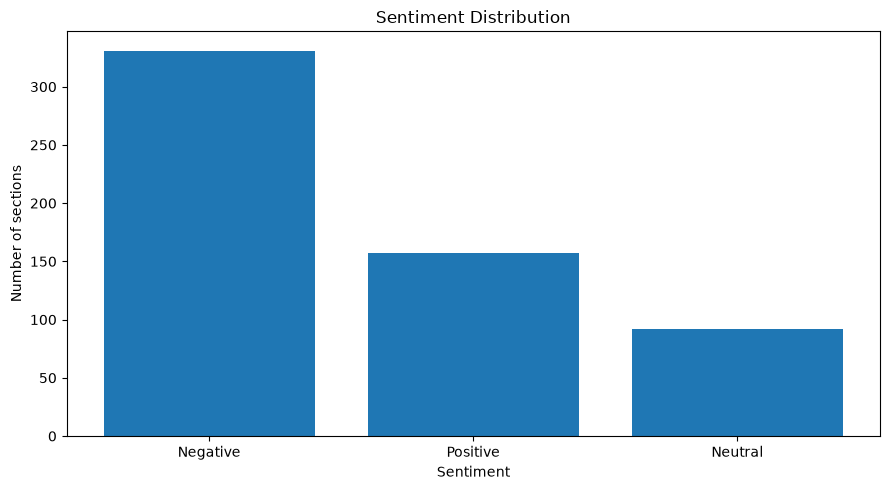

In [9]:

sentiment_df = (
    results_df["sentiment"]
    .value_counts()
    .rename_axis("sentiment")
    .reset_index(name="count")
)

display(sentiment_df)

plt.figure(figsize=(9, 5))
plt.bar(sentiment_df["sentiment"], sentiment_df["count"])
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of sections")
plt.tight_layout()
plt.show()


## 8. Tone distribution

,tone,count
0,Concerned,231
1,Neutral/Informational,152
2,Constructive,92
3,Critical,82
4,Urgent,11
5,Diplomatic,6
6,Optimistic,6


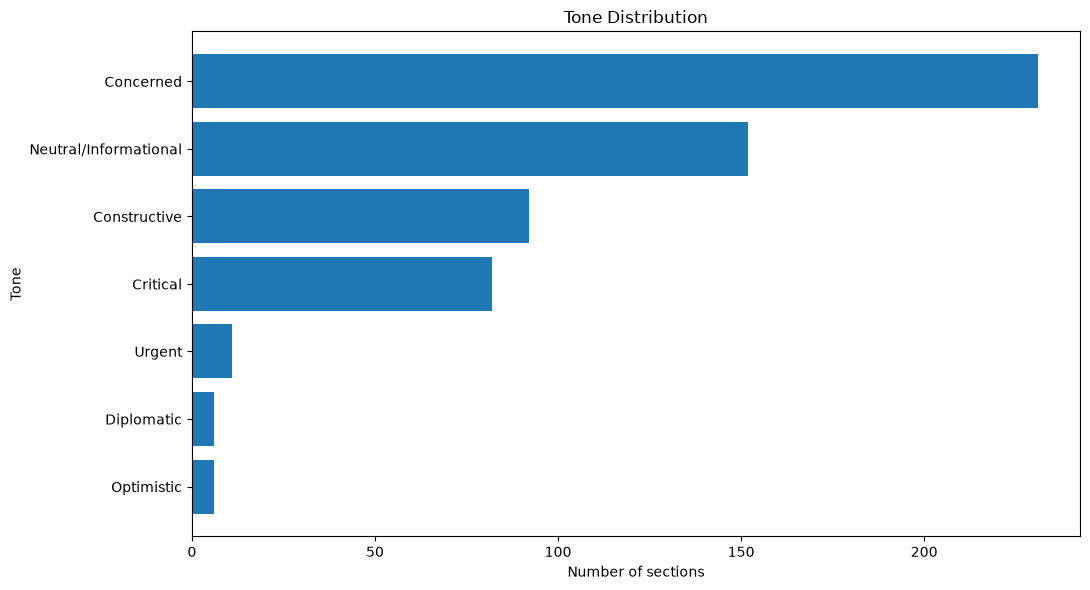

In [10]:

tone_df = (
    results_df["tone"]
    .value_counts()
    .rename_axis("tone")
    .reset_index(name="count")
)

display(tone_df)

plt.figure(figsize=(11, 6))
plt.barh(tone_df["tone"][::-1], tone_df["count"][::-1])
plt.title("Tone Distribution")
plt.xlabel("Number of sections")
plt.ylabel("Tone")
plt.tight_layout()
plt.show()


## 9. Sentiment percentage

,sentiment,count,percentage
0,Negative,331,57.068966
1,Positive,157,27.068966
2,Neutral,92,15.862069


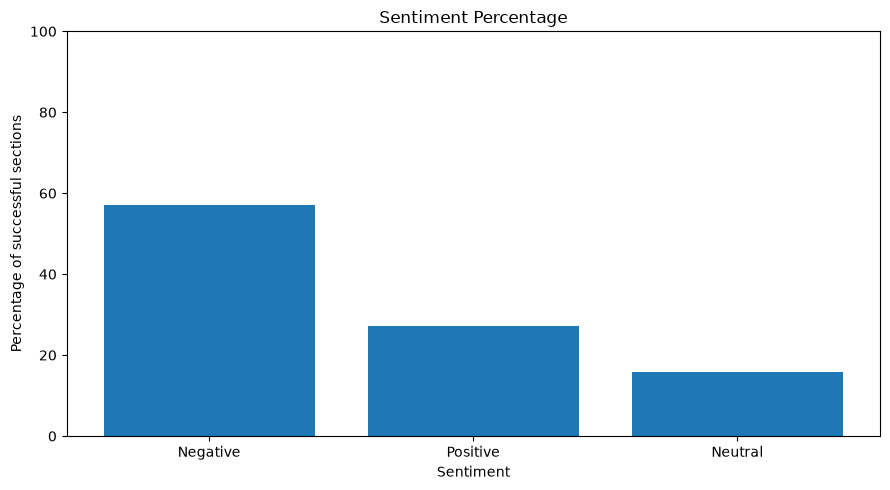

In [11]:

sentiment_percentage_df = sentiment_df.copy()
sentiment_percentage_df["percentage"] = (
    sentiment_percentage_df["count"] /
    sentiment_percentage_df["count"].sum() * 100
)

display(sentiment_percentage_df)

plt.figure(figsize=(9, 5))
plt.bar(
    sentiment_percentage_df["sentiment"],
    sentiment_percentage_df["percentage"]
)
plt.title("Sentiment Percentage")
plt.xlabel("Sentiment")
plt.ylabel("Percentage of successful sections")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


## 10. Prepare monthly data

In [12]:

results_df["month"] = results_df["briefing_date"].dt.to_period("M").astype(str)

monthly_sentiment = (
    results_df
    .groupby(["month", "sentiment"])
    .size()
    .reset_index(name="count")
)

monthly_sentiment_pivot = (
    monthly_sentiment
    .pivot(index="month", columns="sentiment", values="count")
    .fillna(0)
    .sort_index()
)

display(monthly_sentiment_pivot.head(12))


sentiment,Negative,Neutral,Positive
month,,,
2025-08,111,31,43
2025-09,141,29,61
2025-10,79,32,53


## 11. Sentiment over time

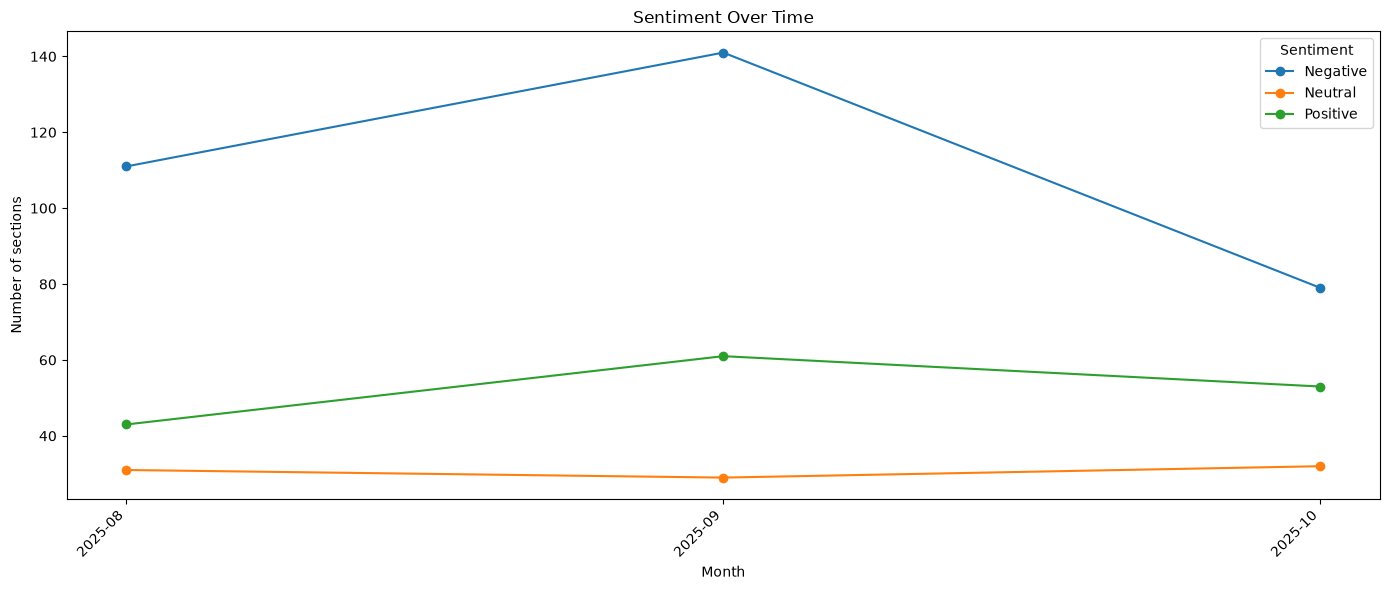

In [13]:

plt.figure(figsize=(14, 6))

for sentiment in monthly_sentiment_pivot.columns:
    plt.plot(
        monthly_sentiment_pivot.index,
        monthly_sentiment_pivot[sentiment],
        marker="o",
        label=sentiment
    )

plt.title("Sentiment Over Time")
plt.xlabel("Month")
plt.ylabel("Number of sections")

step = max(1, len(monthly_sentiment_pivot.index) // 12)
tick_positions = list(range(0, len(monthly_sentiment_pivot.index), step))
plt.xticks(
    tick_positions,
    monthly_sentiment_pivot.index[tick_positions],
    rotation=45,
    ha="right"
)

plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()


## 12. Sentiment percentage over time

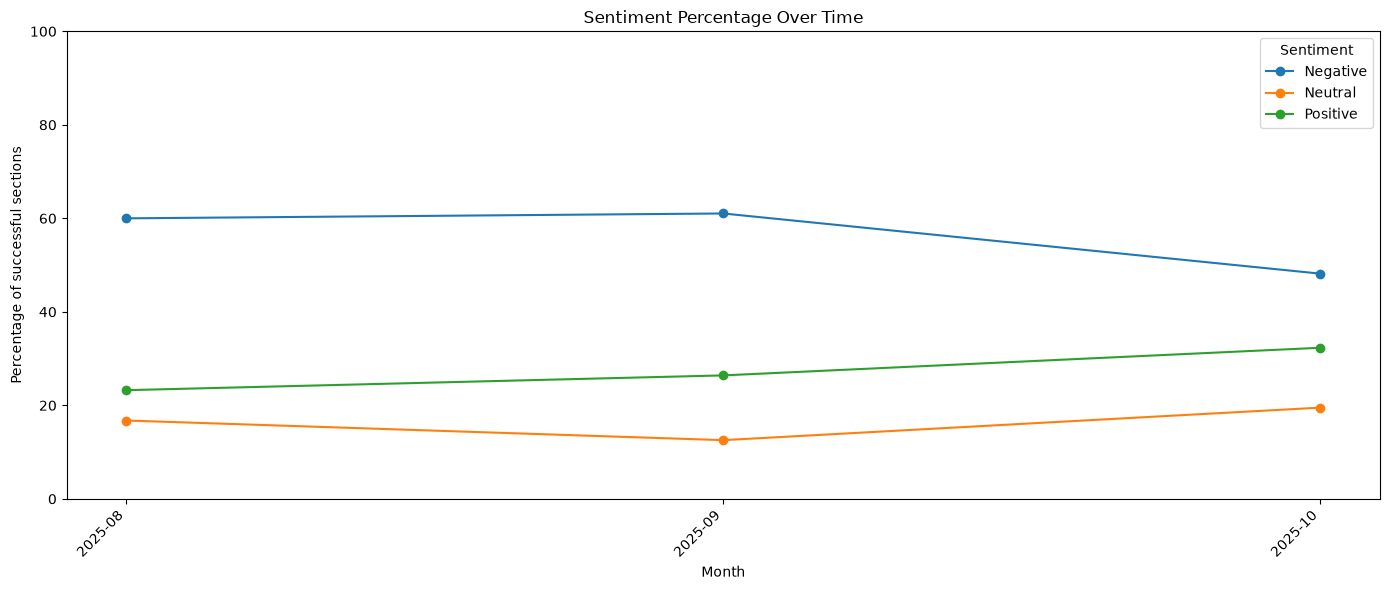

In [14]:

monthly_sentiment_pct = monthly_sentiment_pivot.div(
    monthly_sentiment_pivot.sum(axis=1),
    axis=0
) * 100

plt.figure(figsize=(14, 6))

for sentiment in monthly_sentiment_pct.columns:
    plt.plot(
        monthly_sentiment_pct.index,
        monthly_sentiment_pct[sentiment],
        marker="o",
        label=sentiment
    )

plt.title("Sentiment Percentage Over Time")
plt.xlabel("Month")
plt.ylabel("Percentage of successful sections")
plt.ylim(0, 100)

step = max(1, len(monthly_sentiment_pct.index) // 12)
tick_positions = list(range(0, len(monthly_sentiment_pct.index), step))
plt.xticks(
    tick_positions,
    monthly_sentiment_pct.index[tick_positions],
    rotation=45,
    ha="right"
)

plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()


## 13. Tone over time

tone,Concerned,Constructive,Critical,Diplomatic,Neutral/Informational,Optimistic,Urgent
month,,,,,,,
2025-08,71.0,21.0,29.0,3.0,56.0,1.0,4.0
2025-09,101.0,35.0,34.0,0.0,53.0,4.0,4.0
2025-10,59.0,36.0,19.0,3.0,43.0,1.0,3.0


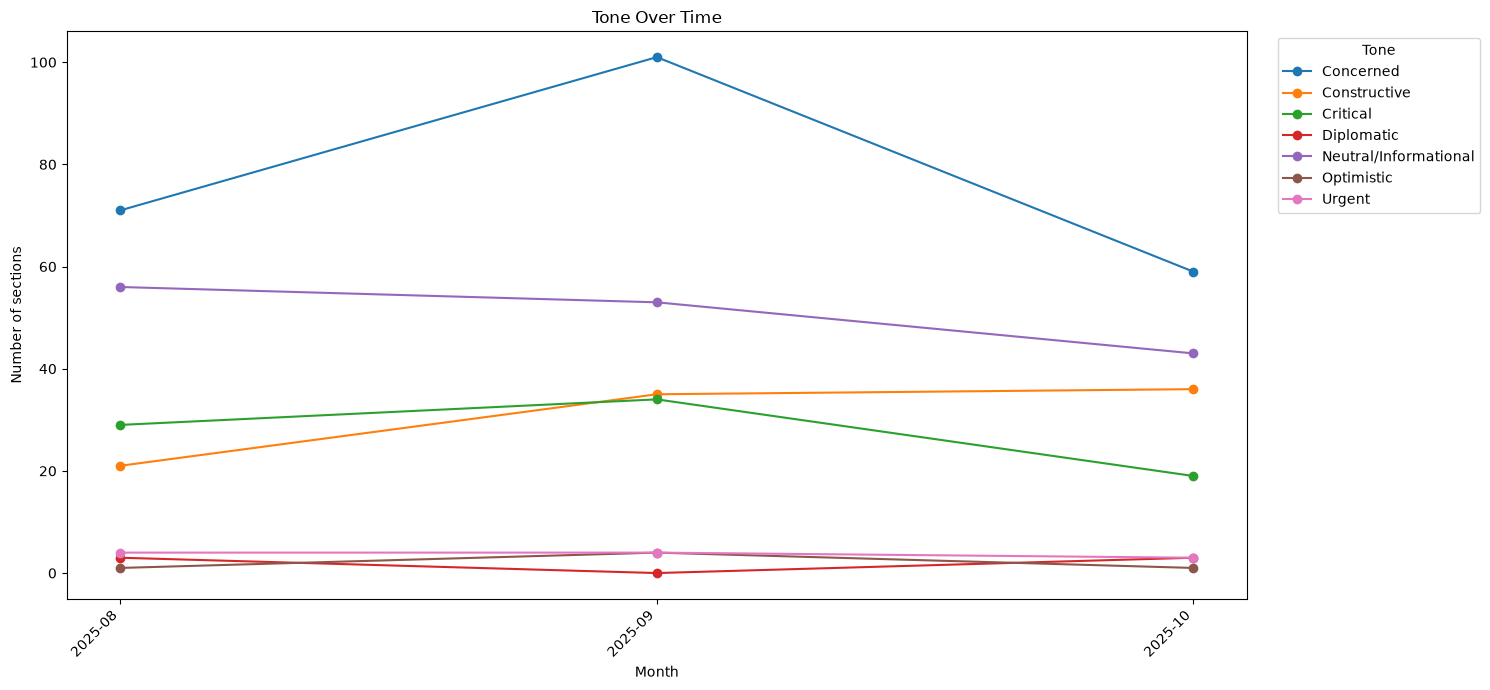

In [15]:

monthly_tone = (
    results_df
    .groupby(["month", "tone"])
    .size()
    .reset_index(name="count")
)

monthly_tone_pivot = (
    monthly_tone
    .pivot(index="month", columns="tone", values="count")
    .fillna(0)
    .sort_index()
)

display(monthly_tone_pivot.head(12))

plt.figure(figsize=(15, 7))

for tone in monthly_tone_pivot.columns:
    plt.plot(
        monthly_tone_pivot.index,
        monthly_tone_pivot[tone],
        marker="o",
        label=tone
    )

plt.title("Tone Over Time")
plt.xlabel("Month")
plt.ylabel("Number of sections")

step = max(1, len(monthly_tone_pivot.index) // 12)
tick_positions = list(range(0, len(monthly_tone_pivot.index), step))
plt.xticks(
    tick_positions,
    monthly_tone_pivot.index[tick_positions],
    rotation=45,
    ha="right"
)

plt.legend(
    title="Tone",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


## 14. Sentiment × tone heatmap

tone,Concerned,Constructive,Critical,Diplomatic,Neutral/Informational,Optimistic,Urgent
sentiment,,,,,,,
Negative,223,5,82,1,10,0,10
Neutral,3,13,0,0,76,0,0
Positive,5,74,0,5,66,6,1


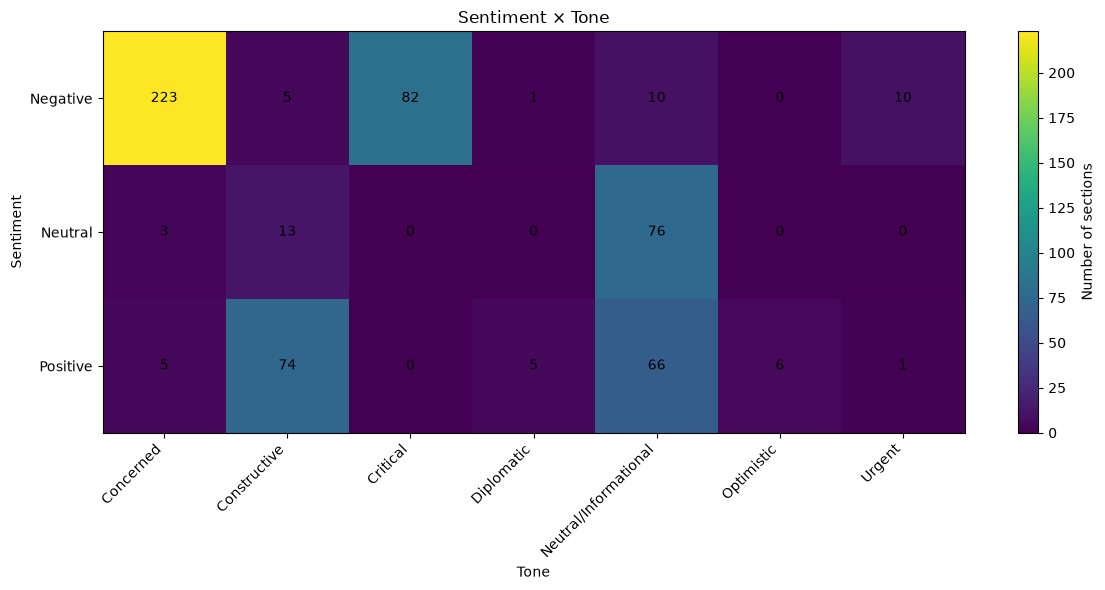

In [16]:

sentiment_tone_crosstab = pd.crosstab(
    results_df["sentiment"],
    results_df["tone"]
)

display(sentiment_tone_crosstab)

plt.figure(figsize=(12, 6))
plt.imshow(sentiment_tone_crosstab.values, aspect="auto")

plt.title("Sentiment × Tone")
plt.xlabel("Tone")
plt.ylabel("Sentiment")

plt.xticks(
    range(len(sentiment_tone_crosstab.columns)),
    sentiment_tone_crosstab.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(sentiment_tone_crosstab.index)),
    sentiment_tone_crosstab.index
)

for i in range(sentiment_tone_crosstab.shape[0]):
    for j in range(sentiment_tone_crosstab.shape[1]):
        plt.text(
            j, i,
            int(sentiment_tone_crosstab.iloc[i, j]),
            ha="center",
            va="center"
        )

plt.colorbar(label="Number of sections")
plt.tight_layout()
plt.show()


## 15. Monthly sentiment composition — 100% stacked bar

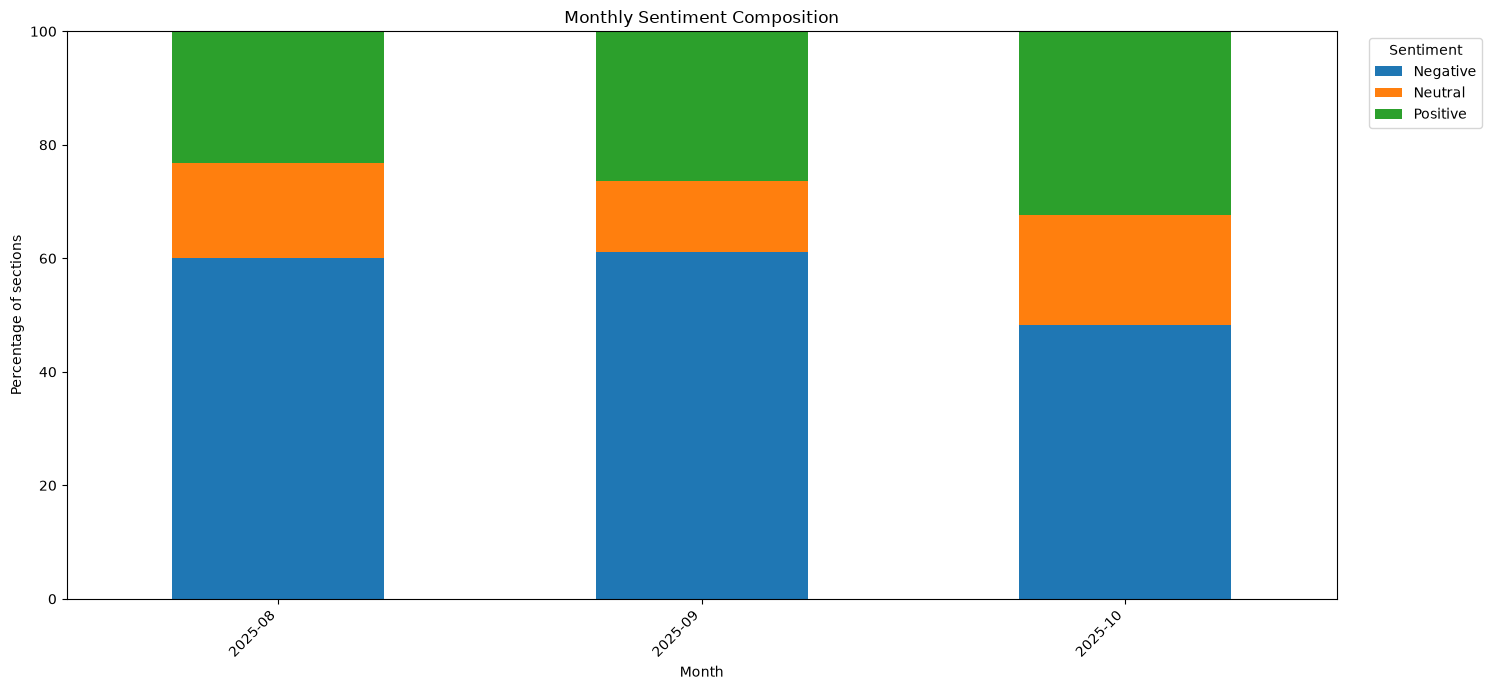

In [17]:

ax = monthly_sentiment_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(15, 7)
)

ax.set_title("Monthly Sentiment Composition")
ax.set_xlabel("Month")
ax.set_ylabel("Percentage of sections")
ax.set_ylim(0, 100)

plt.xticks(rotation=45, ha="right")
plt.legend(
    title="Sentiment",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()


## 16. Number of analysed sections per month

,month,sections
0,2025-08,185
1,2025-09,231
2,2025-10,164


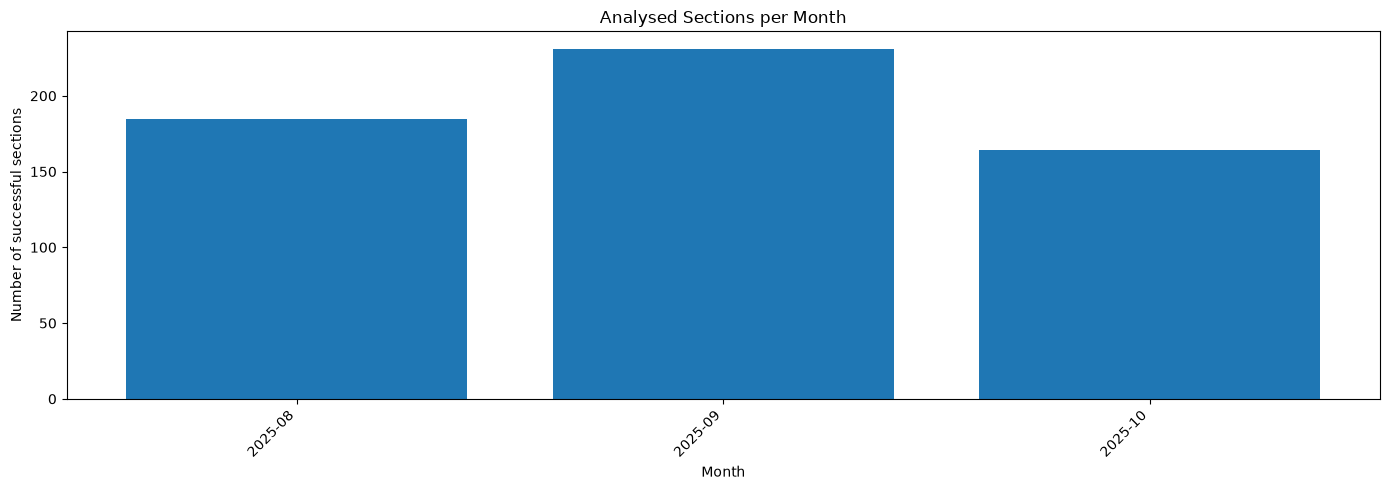

In [18]:

monthly_volume = (
    results_df
    .groupby("month")
    .size()
    .reset_index(name="sections")
)

display(monthly_volume.head(12))

plt.figure(figsize=(14, 5))
plt.bar(monthly_volume["month"], monthly_volume["sections"])
plt.title("Analysed Sections per Month")
plt.xlabel("Month")
plt.ylabel("Number of successful sections")

step = max(1, len(monthly_volume) // 12)
tick_positions = list(range(0, len(monthly_volume), step))
plt.xticks(
    tick_positions,
    monthly_volume["month"].iloc[tick_positions],
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()



## 17. Sentiment composition by briefing

The first 30 chronological briefings are displayed to keep the chart readable.
The underlying data is not truncated when exported.


,Negative,Neutral,Positive,briefing_date
briefing_id,,,,
20250801,3,3,1,2025-08-01
20250804,6,1,1,2025-08-04
20250805,4,1,2,2025-08-05
20250806,6,0,1,2025-08-06
20250807,7,1,0,2025-08-07
20250808,5,1,5,2025-08-08
20250811,8,2,3,2025-08-11
20250812,5,1,2,2025-08-12
20250813,3,1,1,2025-08-13


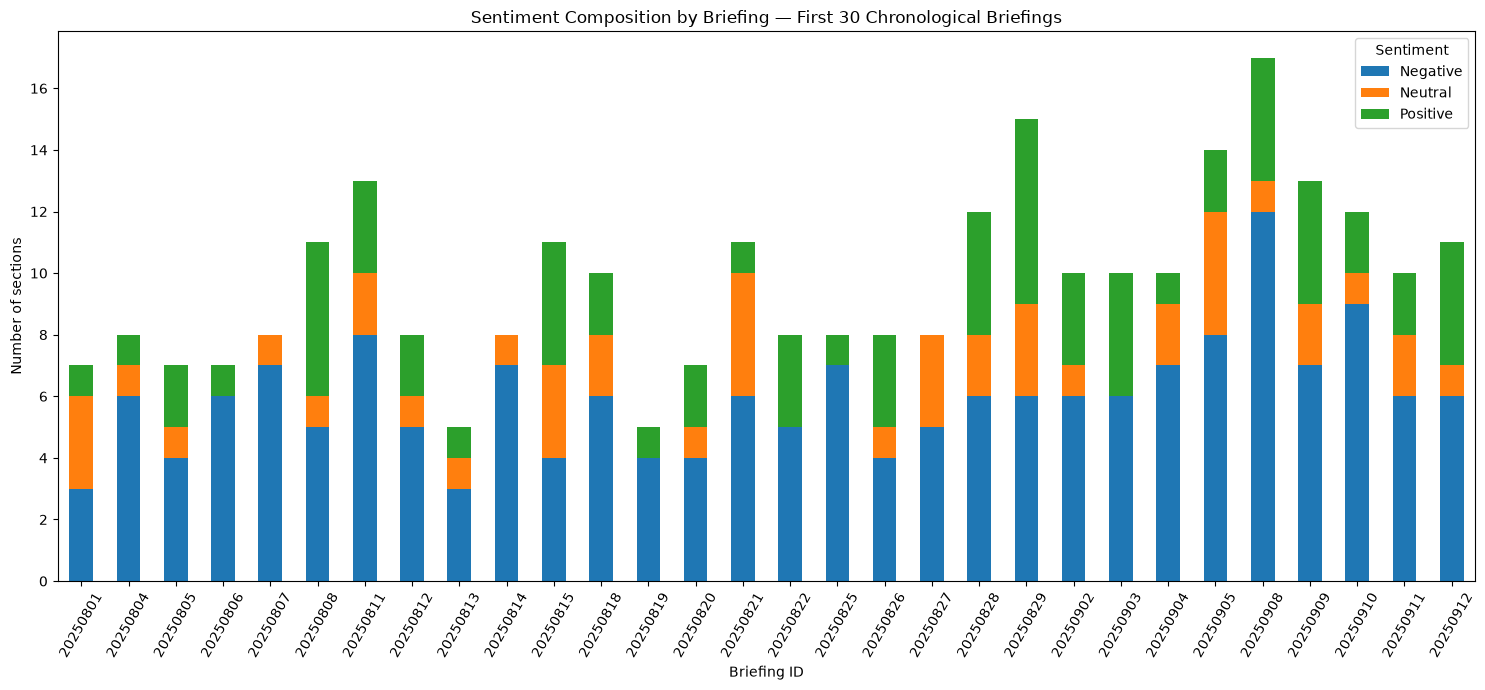

In [19]:

briefing_sentiment = pd.crosstab(
    results_df["briefing_id"],
    results_df["sentiment"]
)

briefing_dates = (
    results_df[["briefing_id", "briefing_date"]]
    .drop_duplicates("briefing_id")
    .set_index("briefing_id")
)

briefing_sentiment = briefing_sentiment.join(briefing_dates)
briefing_sentiment = briefing_sentiment.sort_values("briefing_date")

display(briefing_sentiment.head(10))

plot_df = briefing_sentiment.head(30).drop(
    columns=["briefing_date"],
    errors="ignore"
)

ax = plot_df.plot(
    kind="bar",
    stacked=True,
    figsize=(15, 7)
)

ax.set_title(
    "Sentiment Composition by Briefing — First 30 Chronological Briefings"
)
ax.set_xlabel("Briefing ID")
ax.set_ylabel("Number of sections")

plt.xticks(rotation=60)
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()



## 18. Join results with original section text

The `sentiment_analysis` table stores the classification but not the section title/text.
This cell joins the analysis results back to the original `section` table.

This is useful for qualitative inspection of examples behind the charts.


In [20]:

section_details = pd.read_sql_query(
    '''
    SELECT
        sa.briefing_id,
        sa.section_id,
        sa.briefing_date,
        s.section_order,
        s.title,
        s.text AS section_text,
        sa.sentiment,
        sa.tone
    FROM sentiment_analysis AS sa
    LEFT JOIN section AS s
        ON s.section_id = sa.section_id
    WHERE sa.analysis_id = ?
      AND sa.status = 'success'
    ORDER BY sa.briefing_date, s.section_order
    ''',
    conn,
    params=(ANALYSIS_ID,)
)

section_details["briefing_date"] = pd.to_datetime(
    section_details["briefing_date"], errors="coerce"
)

print(f"Rows with section details: {len(section_details):,}")
display(section_details.head())


Rows with section details: 600


,briefing_id,section_id,briefing_date,section_order,title,section_text,sentiment,tone
0,20250801,2025080101,2025-08-01,1,TRIP ANNOUNCEMENT,"The Secretary-General will travel to Central Asia this weekend. On Sunday, the Secretary-General and the President o...",Positive,Neutral/Informational
1,20250801,2025080102,2025-08-01,2,DEPUTY SECRETARY-GENERAL/ TRAVEL,"In Amman, Jordan today, the Deputy Secretary-General, Amina Mohammed, is chairing the final session of the Regional ...",Neutral,Neutral/Informational
2,20250801,2025080103,2025-08-01,3,OCCUPIED PALESTINIAN TERRITORY,"Turning to Gaza, the Office for the Coordination of Humanitarian Affairs says that large numbers of people reportedl...",Negative,Concerned
3,20250801,2025080104,2025-08-01,4,HAITI,"Earlier today, our colleagues in Haiti published their quarterly report on the human rights situation in the country...",Negative,Concerned
4,20250801,2025080105,2025-08-01,5,HAITI - HUMANITARIAN,"Adding to the human rights report, the Office for the Coordination of Humanitarian Affairs is telling us that in the...",Negative,Urgent


## 19. Inspect examples for each sentiment

In [21]:

for sentiment in ["Positive", "Neutral", "Negative"]:
    subset = section_details[
        section_details["sentiment"].eq(sentiment)
    ][
        ["briefing_date", "section_id", "title", "tone", "section_text"]
    ].head(5)

    print(f"\n===== {sentiment} examples =====")
    display(subset)



===== Positive examples =====


,briefing_date,section_id,title,tone,section_text
0,2025-08-01,2025080101,TRIP ANNOUNCEMENT,Neutral/Informational,"The Secretary-General will travel to Central Asia this weekend. On Sunday, the Secretary-General and the President o..."
14,2025-08-04,2025080408,NEW RESIDENT COORDINATORS,Neutral/Informational,"The UN Development Coordination Office (DCO) informs us that on 3 August, Caroline Tissot of Switzerland assumed her..."
16,2025-08-05,2025080502,SECRETARY-GENERAL / CONFERENCE ON LANDLOCKED DEVELOPING COUNTRIES,Constructive,"Today, the Secretary-General officially opened the Third United Nations Conference on Landlocked Developing Countrie..."
21,2025-08-05,2025080507,INDIA/UN PARTNERSHIP FOR SOUTH-SOUTH COOPERATION ON THE SDGS,Neutral/Informational,"At the beginning of the month, the Government of India and the UN team in the country launched the first set of proj..."
28,2025-08-06,2025080607,FINANCIAL CONTRIBUTION,Neutral/Informational,"Mozambique has made its full payment to the Regular Budget, bringing the number of fully paid-up Member States to 118."



===== Neutral examples =====


,briefing_date,section_id,title,tone,section_text
1,2025-08-01,2025080102,DEPUTY SECRETARY-GENERAL/ TRAVEL,Neutral/Informational,"In Amman, Jordan today, the Deputy Secretary-General, Amina Mohammed, is chairing the final session of the Regional ..."
5,2025-08-01,2025080106,SECURITY COUNCIL/AFTERNOON,Neutral/Informational,"At 3:00 p.m. today, the Security Council will hold a briefing on the Maintenance of peace and security of Ukraine. M..."
6,2025-08-01,2025080107,WORLD BREASTFEEDING WEEK,Neutral/Informational,World Breastfeeding Week begins today and it will continue until 7 August. This year’s theme is ‘Invest in breastfee...
7,2025-08-04,2025080401,SECRETARY-GENERAL/TRAVEL,Neutral/Informational,The Secretary-General is in Awaza in Turkmenistan. He will attend the Third United Nations Conference on Landlocked ...
15,2025-08-05,2025080501,"HIGHLIGHTS OF THE NOON BRIEFING BY FARHAN HAQ,",Neutral/Informational,"**DEPUTY SPOKESMAN FOR SECRETARY-GENERAL ANTÓNIO GUTERRES\nTUESDAY, 5 AUGUST 2025**"



===== Negative examples =====


,briefing_date,section_id,title,tone,section_text
2,2025-08-01,2025080103,OCCUPIED PALESTINIAN TERRITORY,Concerned,"Turning to Gaza, the Office for the Coordination of Humanitarian Affairs says that large numbers of people reportedl..."
3,2025-08-01,2025080104,HAITI,Concerned,"Earlier today, our colleagues in Haiti published their quarterly report on the human rights situation in the country..."
4,2025-08-01,2025080105,HAITI - HUMANITARIAN,Urgent,"Adding to the human rights report, the Office for the Coordination of Humanitarian Affairs is telling us that in the..."
8,2025-08-04,2025080402,OCCUPIED PALESTINIAN TERRITORY,Critical,"In response to questions about the videos of the Israeli hostages shown by Hamas, the Deputy Spokesperson said the S..."
9,2025-08-04,2025080403,UNIFIL,Concerned,"In southern Lebanon, the peacekeepers of the UN Interim Force in Lebanon have observed continued Israel Defense Forc..."


## 20. Inspect examples for each tone

In [22]:

for tone in sorted(section_details["tone"].dropna().unique()):
    subset = section_details[
        section_details["tone"].eq(tone)
    ][
        ["briefing_date", "section_id", "title", "sentiment", "section_text"]
    ].head(3)

    print(f"\n===== {tone} examples =====")
    display(subset)



===== Concerned examples =====


,briefing_date,section_id,title,sentiment,section_text
2,2025-08-01,2025080103,OCCUPIED PALESTINIAN TERRITORY,Negative,"Turning to Gaza, the Office for the Coordination of Humanitarian Affairs says that large numbers of people reportedl..."
3,2025-08-01,2025080104,HAITI,Negative,"Earlier today, our colleagues in Haiti published their quarterly report on the human rights situation in the country..."
9,2025-08-04,2025080403,UNIFIL,Negative,"In southern Lebanon, the peacekeepers of the UN Interim Force in Lebanon have observed continued Israel Defense Forc..."



===== Constructive examples =====


,briefing_date,section_id,title,sentiment,section_text
16,2025-08-05,2025080502,SECRETARY-GENERAL / CONFERENCE ON LANDLOCKED DEVELOPING COUNTRIES,Positive,"Today, the Secretary-General officially opened the Third United Nations Conference on Landlocked Developing Countrie..."
41,2025-08-08,2025080805,MOZAMBIQUE,Positive,"Following the recent sharp surge in displacement in Cabo Delgado province, in Mozambique, amid escalating violence, ..."
46,2025-08-08,2025080810,INDIGENOUS PEOPLES,Positive,"Tomorrow, it is the International Day of the World’s Indigenous Peoples. In his message for the Day, the Secretary-G..."



===== Critical examples =====


,briefing_date,section_id,title,sentiment,section_text
8,2025-08-04,2025080402,OCCUPIED PALESTINIAN TERRITORY,Negative,"In response to questions about the videos of the Israeli hostages shown by Hamas, the Deputy Spokesperson said the S..."
13,2025-08-04,2025080407,UGANDA,Negative,"The UN Refugee Agency says that by the end of the year, Uganda could be hosting two million refugees. This is happen..."
19,2025-08-05,2025080505,SUDAN,Negative,"The Under-Secretary-General for Humanitarian Affairs, Tom Fletcher today warned that with the risk of starvation on ..."


... (4 outputs left out)


===== Optimistic examples =====


,briefing_date,section_id,title,sentiment,section_text
142,2025-08-26,2025082601,ARTIFICIAL INTELLIGENCE,Positive,The Secretary-General warmly welcomes the General Assembly's decision to establish two new mechanisms within the Uni...
307,2025-09-16,2025091604,PRESERVATION OF THE OZONE LAYER,Positive,"Today is the International Day for the Preservation of the Ozone Layer. In his message for the Day, the Secretary-Ge..."
357,2025-09-24,2025092402,CLIMATE,Positive,"At 2:00 p.m. this afternoon, a High-Level Special Event on Climate Action will take place in the Trusteeship Council..."



===== Urgent examples =====


,briefing_date,section_id,title,sentiment,section_text
4,2025-08-01,2025080105,HAITI - HUMANITARIAN,Negative,"Adding to the human rights report, the Office for the Coordination of Humanitarian Affairs is telling us that in the..."
36,2025-08-07,2025080708,AFGHANISTAN,Negative,The International Organization for Migration (IOM) is urgently calling for international support as Afghanistan face...
65,2025-08-12,2025081205,MYANMAR,Negative,"The World Food Programme (WFP) is urgently calling for more humanitarian support in Rakhine State, where a deadly co..."


## 21. Export visualization datasets

In [23]:

exports = {
    "sentiment_distribution.csv": sentiment_df,
    "tone_distribution.csv": tone_df,
    "sentiment_percentage.csv": sentiment_percentage_df,
    "monthly_sentiment.csv": monthly_sentiment,
    "monthly_sentiment_percentage.csv": monthly_sentiment_pct.reset_index(),
    "monthly_tone.csv": monthly_tone,
    "monthly_volume.csv": monthly_volume,
    "sentiment_tone_crosstab.csv": sentiment_tone_crosstab.reset_index(),
    "section_sentiment_tone_results.csv": section_details,
}

for filename, data in exports.items():
    path = OUTPUT_DIR / filename
    data.to_csv(path, index=False)
    print(f"Saved: {path}")


Saved: E:\correlaid-mentoring-project\data\visualization\sentiment_distribution.csv
Saved: E:\correlaid-mentoring-project\data\visualization\tone_distribution.csv
Saved: E:\correlaid-mentoring-project\data\visualization\sentiment_percentage.csv
Saved: E:\correlaid-mentoring-project\data\visualization\monthly_sentiment.csv
Saved: E:\correlaid-mentoring-project\data\visualization\monthly_sentiment_percentage.csv
Saved: E:\correlaid-mentoring-project\data\visualization\monthly_tone.csv
Saved: E:\correlaid-mentoring-project\data\visualization\monthly_volume.csv
Saved: E:\correlaid-mentoring-project\data\visualization\sentiment_tone_crosstab.csv
Saved: E:\correlaid-mentoring-project\data\visualization\section_sentiment_tone_results.csv


## 22. Create one dashboard-ready dataset

In [24]:

dashboard_df = section_details.copy()
dashboard_df["month"] = dashboard_df["briefing_date"].dt.to_period("M").astype(str)

dashboard_path = OUTPUT_DIR / "UN_sentiment_tone_dashboard_data.csv"
dashboard_df.to_csv(dashboard_path, index=False)

print("Dashboard-ready dataset:")
print(dashboard_path)
print(f"Rows: {len(dashboard_df):,}")

display(dashboard_df.head())


Dashboard-ready dataset:
E:\correlaid-mentoring-project\data\visualization\UN_sentiment_tone_dashboard_data.csv
Rows: 600


,briefing_id,section_id,briefing_date,section_order,title,section_text,sentiment,tone,month
0,20250801,2025080101,2025-08-01,1,TRIP ANNOUNCEMENT,"The Secretary-General will travel to Central Asia this weekend. On Sunday, the Secretary-General and the President o...",Positive,Neutral/Informational,2025-08
1,20250801,2025080102,2025-08-01,2,DEPUTY SECRETARY-GENERAL/ TRAVEL,"In Amman, Jordan today, the Deputy Secretary-General, Amina Mohammed, is chairing the final session of the Regional ...",Neutral,Neutral/Informational,2025-08
2,20250801,2025080103,2025-08-01,3,OCCUPIED PALESTINIAN TERRITORY,"Turning to Gaza, the Office for the Coordination of Humanitarian Affairs says that large numbers of people reportedl...",Negative,Concerned,2025-08
3,20250801,2025080104,2025-08-01,4,HAITI,"Earlier today, our colleagues in Haiti published their quarterly report on the human rights situation in the country...",Negative,Concerned,2025-08
4,20250801,2025080105,2025-08-01,5,HAITI - HUMANITARIAN,"Adding to the human rights report, the Office for the Coordination of Humanitarian Affairs is telling us that in the...",Negative,Urgent,2025-08


## 23. Final visualization summary

In [25]:

print("=" * 70)
print("UN NOON BRIEFINGS — VISUALIZATION SUMMARY")
print("=" * 70)
print(f"Analysis ID:                  {ANALYSIS_ID}")
print(f"Successful analysed sections: {len(results_df):,}")
print(f"Unique briefings:             {results_df['briefing_id'].nunique():,}")
print(
    "Date range:                   "
    f"{results_df['briefing_date'].min().date()} "
    f"to {results_df['briefing_date'].max().date()}"
)
print(
    "Sentiment categories:         "
    + ", ".join(map(str, results_df["sentiment"].dropna().unique()))
)
print(
    "Tone categories:              "
    + ", ".join(map(str, results_df["tone"].dropna().unique()))
)
print(f"Output directory:             {OUTPUT_DIR}")
print("=" * 70)


UN NOON BRIEFINGS — VISUALIZATION SUMMARY
Analysis ID:                  17
Successful analysed sections: 580
Unique briefings:             60
Date range:                   2025-08-01 to 2025-10-24
Sentiment categories:         Positive, Neutral, Negative
Tone categories:              Neutral/Informational, Concerned, Urgent, Critical, Constructive, Diplomatic, Optimistic
Output directory:             E:\correlaid-mentoring-project\data\visualization


# 24. Close the database connection

In [26]:

conn.close()
print("Database connection closed.")


Database connection closed.


# 25. References

 OpenAI ChatGPT — used as an AI coding assistant for developing  part of this notebook.
  https://chatgpt.com/